# Heart Disease Prediction

Run the cells in order. When the last section asks for input, type each answer below the cell. This is a class project and its predictions aren't a medical diagnosis.

In [ ]:
%pip -q install pandas numpy matplotlib seaborn scikit-learn


In [ ]:
# ============================================================
# HEART DISEASE PREDICTION USING MACHINE LEARNING
# ============================================================

# -------------------- IMPORT LIBRARIES --------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)


## Load and check the data

In [ ]:
print("\n========================================")
print("   HEART DISEASE PREDICTION")
print("========================================\n")

url = "https://raw.githubusercontent.com/imteekay/heart-failure-prediction/main/heart.csv"

try:
    df = pd.read_csv(url)
    print("Dataset loaded successfully!")
except Exception as e:
    print("Error while loading dataset.")
    print("Please check your internet connection.")
    print(e)
    exit()


In [ ]:
print("\n========== FIRST 5 ROWS ==========")
print(df.head())

print("\n========== DATASET SHAPE ==========")
print(df.shape)

print("\n========== COLUMN NAMES ==========")
print(df.columns.tolist())

print("\n========== DATA TYPES ==========")
print(df.dtypes)

print("\n========== MISSING VALUES ==========")
print(df.isnull().sum())

print("\n========== DUPLICATE ROWS ==========")
print(df.duplicated().sum())


In [ ]:
df = df.drop_duplicates()
print("\nShape after removing duplicates:", df.shape)


In [ ]:
print("\n========== STATISTICAL SUMMARY ==========")
print(df.describe())


## Explore the data


========== CLASS DISTRIBUTION ==========
HeartDisease
1    508
0    410
Name: count, dtype: int64

Class proportion (normalized):
HeartDisease
1    0.553
0    0.447
Name: proportion, dtype: float64


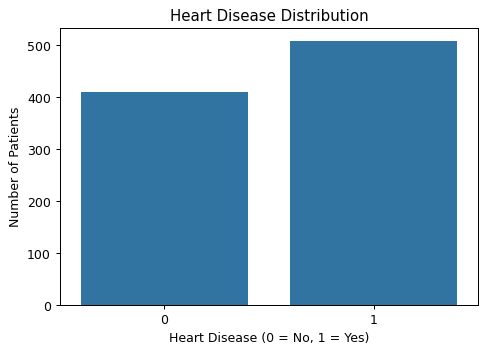

In [ ]:
print("\n========== CLASS DISTRIBUTION ==========")
print(df['HeartDisease'].value_counts())
print("\nClass proportion (normalized):")
print(df['HeartDisease'].value_counts(normalize=True).round(3))

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="HeartDisease")
plt.title("Heart Disease Distribution")
plt.xlabel("Heart Disease (0 = No, 1 = Yes)")
plt.ylabel("Number of Patients")
plt.savefig("plot_target_distribution.png")
plt.show()


### Numerical distributions and unusual values
Each row shows the distribution of one measurement and its spread within each outcome group. Zero cholesterol and resting blood pressure are counted below and treated as unavailable in these EDA plots.

RestingBP: 1 zero readings
Cholesterol: 172 zero readings


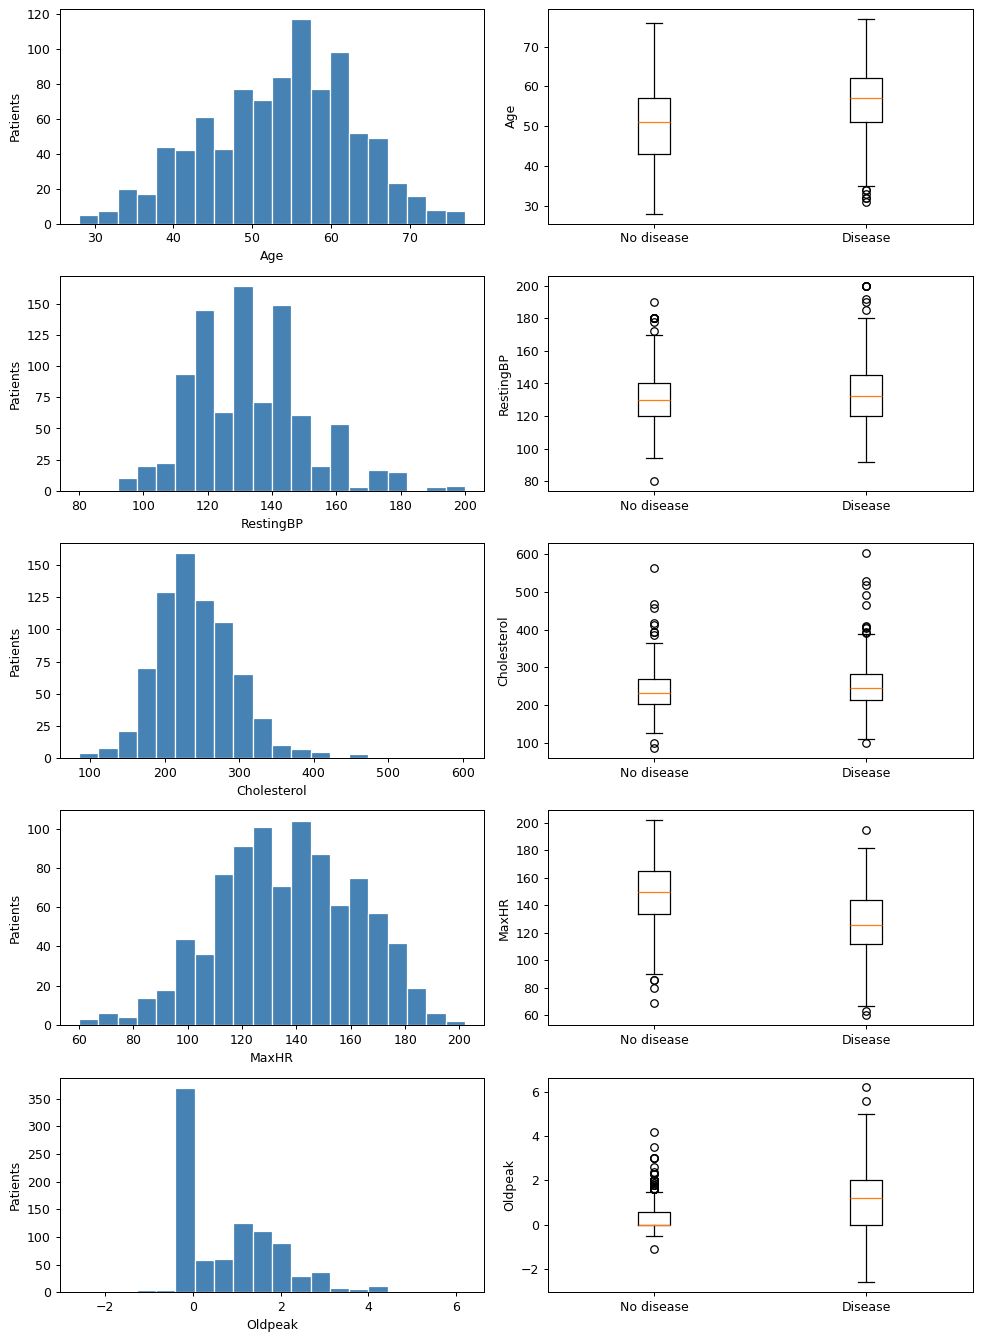

In [ ]:
eda = df.copy()
measurements = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
categories = ['Sex', 'ChestPainType', 'FastingBS', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
for column in ['RestingBP', 'Cholesterol']:
    zeros = eda[column].eq(0)
    print(f'{column}: {zeros.sum()} zero readings')
    eda.loc[zeros, column] = np.nan

fig, axes = plt.subplots(len(measurements), 2, figsize=(11, 15))
for column, (left, right) in zip(measurements, axes):
    left.hist(eda[column].dropna(), bins=20, color='steelblue', edgecolor='white')
    left.set(xlabel=column, ylabel='Patients')
    groups = [eda.loc[eda.HeartDisease == label, column].dropna() for label in [0, 1]]
    right.boxplot(groups)
    right.set_xticks([1, 2], ['No disease', 'Disease'])
    right.set_ylabel(column)
fig.tight_layout()
plt.show()

### Categorical features and heart disease
Counts show the size of each group. The percentage beside each group shows how many patients in that group have a positive label. FastingBS is a binary category.

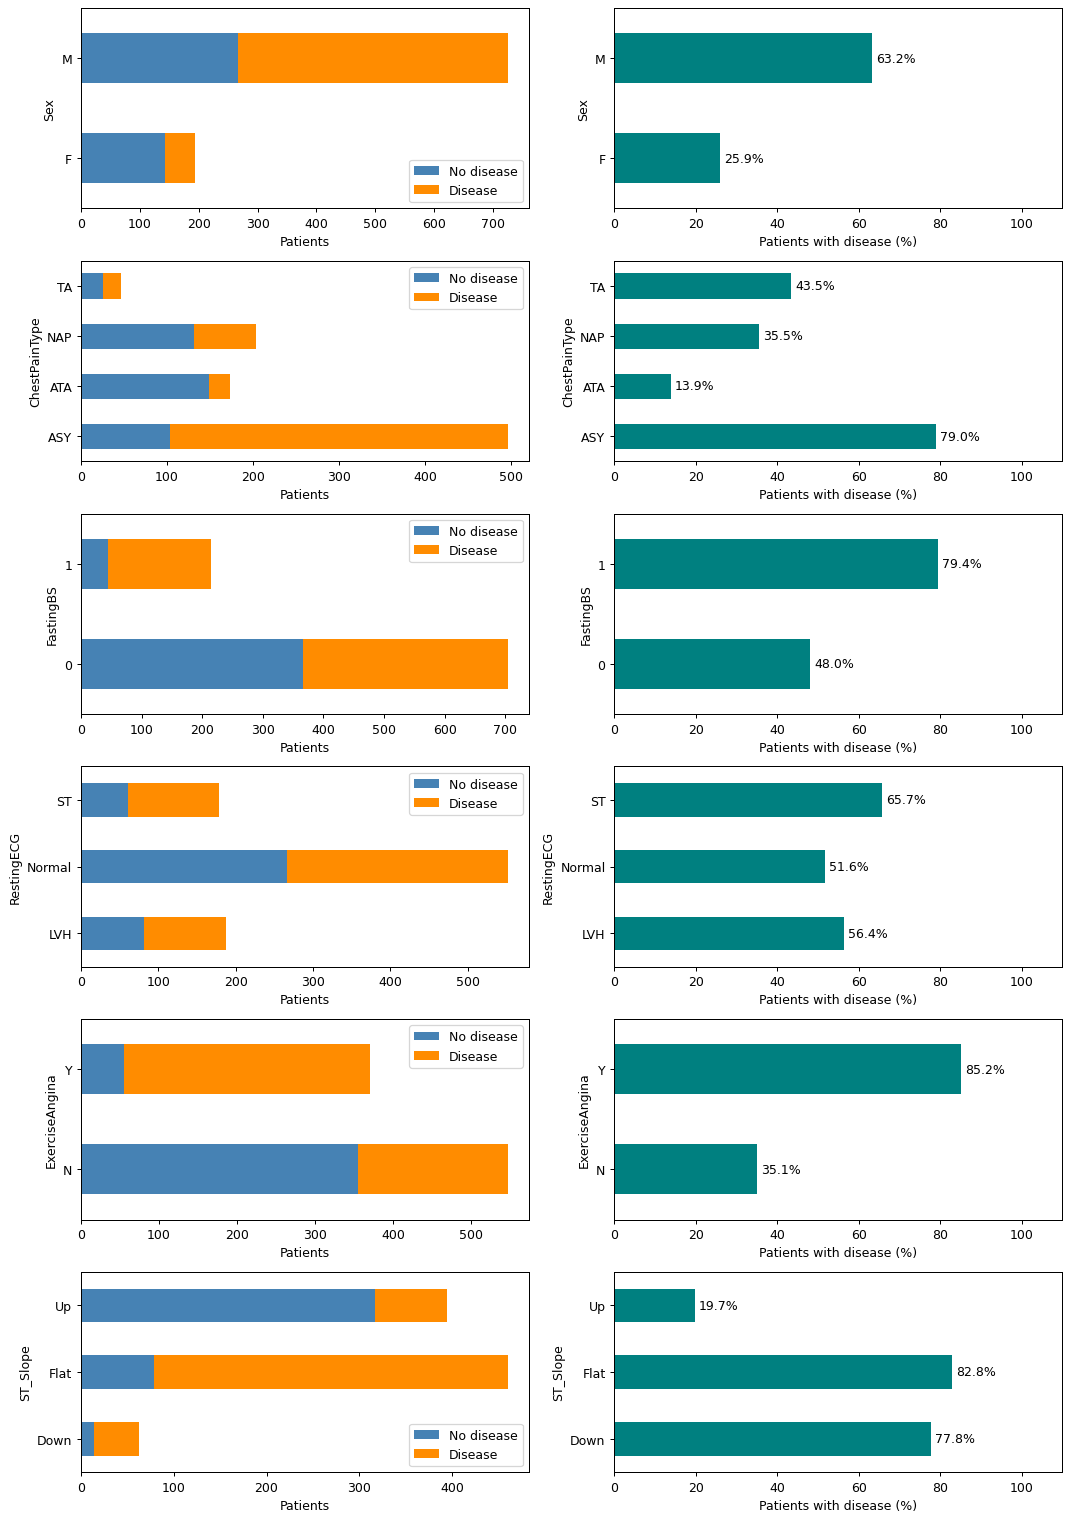

In [ ]:
fig, axes = plt.subplots(len(categories), 2, figsize=(12, 17))
for column, (left, right) in zip(categories, axes):
    counts = pd.crosstab(eda[column], eda['HeartDisease']).reindex(columns=[0, 1], fill_value=0)
    counts.columns = ['No disease', 'Disease']
    counts.plot.barh(stacked=True, ax=left, color=['steelblue', 'darkorange'])
    left.set_xlabel('Patients')
    rate = 100 * counts['Disease'] / counts.sum(axis=1)
    rate.plot.barh(ax=right, color='teal')
    right.set(xlim=(0, 110), xlabel='Patients with disease (%)')
    for row, value in enumerate(rate):
        right.text(value + 1, row, f'{value:.1f}%', va='center')
fig.tight_layout()
plt.show()

### Numerical correlations
Pearson measures linear relationships. Spearman compares ranks. With HeartDisease coded as 0 and 1, a positive Pearson value means the measurement is higher on average in the disease group. Each pair uses rows with both values available.

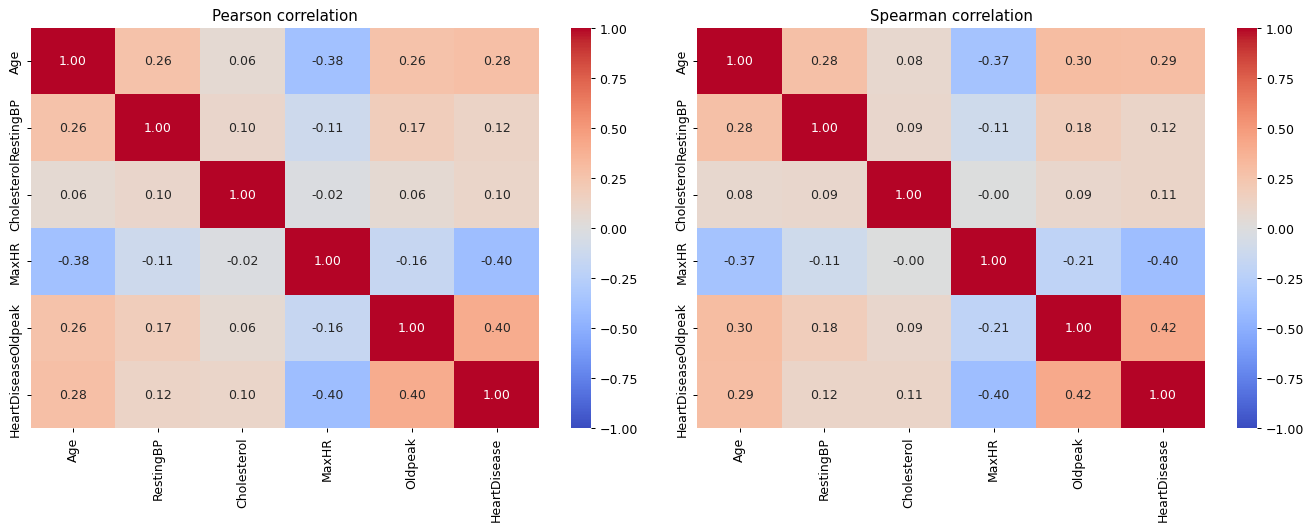

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for method, ax in zip(['pearson', 'spearman'], axes):
    corr = eda[measurements + ['HeartDisease']].corr(method=method)
    sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax)
    ax.set_title(method.title() + ' correlation')
fig.tight_layout()
plt.show()

### Associations between categorical variables
Cramér’s V ranges from 0 to 1. Larger values indicate a stronger association. The group percentages above show which categories have more positive labels.

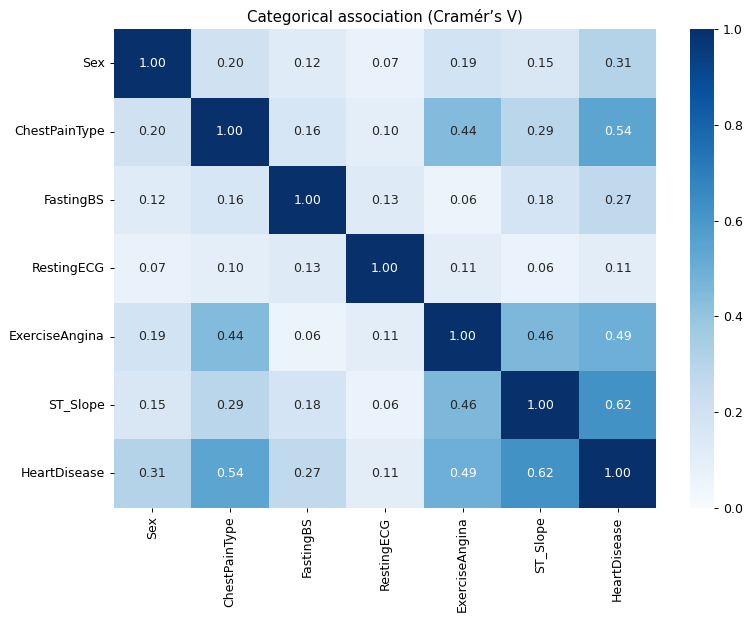

In [ ]:
from scipy.stats import chi2_contingency

columns = categories + ['HeartDisease']
association = pd.DataFrame(np.nan, index=columns, columns=columns)
for i, first in enumerate(columns):
    for second in columns[i:]:
        table = pd.crosstab(eda[first], eda[second])
        dimension = min(table.shape) - 1
        if dimension > 0:
            chi2 = chi2_contingency(table, correction=False)[0]
            value = np.sqrt(chi2 / (table.to_numpy().sum() * dimension))
            association.loc[first, second] = association.loc[second, first] = value

plt.figure(figsize=(9, 7))
sns.heatmap(association, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1)
plt.title("Categorical association (Cramér’s V)")
plt.tight_layout()
plt.show()

## Prepare the data

In [ ]:
X = df.drop("HeartDisease", axis=1)
y = df["HeartDisease"]

print("\n========== FEATURES ==========")
print(X.columns.tolist())

print("\n========== TARGET ==========")
print("HeartDisease")


In [ ]:
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["int64", "float64"]).columns.tolist()

print("\n========== NUMERICAL FEATURES ==========")
print(numeric_features)

print("\n========== CATEGORICAL FEATURES ==========")
print(categorical_features)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("\n========== TRAIN TEST SPLIT ==========")
print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])


In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)


## Train and compare the models

In [ ]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42)
}


In [ ]:
results = []
trained_models = {}

print("\n========================================")
print("       MODEL TRAINING AND TESTING")
print("========================================")

for name, model in models.items():

    print("\n----------------------------------------")
    print(name)
    print("----------------------------------------")

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    # Train model
    pipeline.fit(X_train, y_train)

    # Predict test data
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    # Test-set metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, y_prob)

    # 5-fold cross-validation on F1 (checks the score isn't a lucky split)
    cv_f1_scores = cross_val_score(pipeline, X, y, cv=5, scoring="f1")
    cv_f1_mean = cv_f1_scores.mean()

    print("Accuracy      :", round(accuracy, 4))
    print("Precision     :", round(precision, 4))
    print("Recall        :", round(recall, 4))
    print("F1 Score      :", round(f1, 4))
    print("ROC-AUC       :", round(roc_auc, 4))
    print("CV F1 (5-fold):", round(cv_f1_mean, 4))

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": roc_auc,
        "CV F1 Mean": cv_f1_mean
    })

    trained_models[name] = pipeline


In [ ]:
results_df = pd.DataFrame(results)

print("\n========================================")
print("          MODEL COMPARISON")
print("========================================")
print(results_df.to_string(index=False))


In [ ]:
# We select the best model using CV F1 Mean (5-fold), not the single
# train-test-split F1 score. This avoids picking a model that just got
# "lucky" on one particular split of the data. F1-score is used
# (instead of plain accuracy) because it balances precision and recall,
# which matters here: a false negative (missing a real heart disease
# case) is a more serious mistake than a false positive.

best_model_name = results_df.loc[results_df["CV F1 Mean"].idxmax(), "Model"]
best_model = trained_models[best_model_name]

print("\n========================================")
print("           BEST MODEL")
print("========================================")
print("Best Model:", best_model_name)
print(
    "Best CV F1 Mean:",
    round(results_df.loc[results_df["CV F1 Mean"].idxmax(), "CV F1 Mean"], 4)
)
print("(Selected using 5-fold cross-validated F1-score, not a single split)")


## Check the results

In [ ]:
plt.figure(figsize=(10, 5))
results_melted = results_df.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC", "CV F1 Mean"],
    var_name="Metric",
    value_name="Score"
)
sns.barplot(data=results_melted, x="Model", y="Score", hue="Metric")
plt.title("Model Performance Comparison")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("plot_model_comparison.png")
plt.close()


In [ ]:
best_predictions = best_model.predict(X_test)
cm = confusion_matrix(y_test, best_predictions)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix - " + best_model_name)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.savefig("plot_confusion_matrix.png")
plt.close()


In [ ]:
print("\n========================================")
print("       CLASSIFICATION REPORT")
print("========================================")
print(classification_report(
    y_test, best_predictions,
    target_names=["No Heart Disease", "Heart Disease"]
))


In [ ]:
best_probabilities = best_model.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, best_probabilities)
fpr, tpr, thresholds = roc_curve(y_test, best_probabilities)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label="AUC = " + str(round(roc_auc, 3)))
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - " + best_model_name)
plt.legend()
plt.savefig("plot_roc_curve.png")
plt.close()


## Try a prediction

In [ ]:
def get_valid_input(prompt, valid_options, display_map=None):
    """
    Keeps asking until the user enters something that matches
    one of the valid_options (case-insensitive). display_map lets
    us convert the user's input into the EXACT casing the dataset
    and trained model expect (e.g. 'normal' -> 'Normal').
    """
    while True:
        raw = input(prompt).strip()
        key = raw.upper()
        if display_map and key in display_map:
            return display_map[key]
        if raw in valid_options:
            return raw
        print(f"Invalid input. Please enter one of: {valid_options}")


def get_valid_number(prompt, number_type=int):
    while True:
        raw = input(prompt).strip()
        try:
            return number_type(raw)
        except ValueError:
            print(f"Invalid number. Please enter a valid {number_type.__name__}.")


print("\n")
print("========================================")
print("       NEW PATIENT PREDICTION")
print("========================================")
print("\nEnter the patient's information below.\n")

age = get_valid_number("Age: ", int)

sex = get_valid_input("Sex (M/F): ", ["M", "F"], {"M": "M", "F": "F"})

print("\nChest Pain Types:")
print("TA  = Typical Angina")
print("ATA = Atypical Angina")
print("NAP = Non-Anginal Pain")
print("ASY = Asymptomatic")
chest_pain = get_valid_input(
    "Chest Pain Type: ", ["TA", "ATA", "NAP", "ASY"],
    {"TA": "TA", "ATA": "ATA", "NAP": "NAP", "ASY": "ASY"}
)

resting_bp = get_valid_number("Resting Blood Pressure: ", int)
cholesterol = get_valid_number("Cholesterol: ", int)
fasting_bs = get_valid_number("Fasting Blood Sugar (0/1): ", int)

print("\nResting ECG:")
print("Normal")
print("ST")
print("LVH")
# FIX: dataset uses mixed-case labels ("Normal", "ST", "LVH"), so we
# map the user's case-insensitive input to the EXACT label the model
# was trained on, instead of blindly calling .upper() on it.
resting_ecg = get_valid_input(
    "Resting ECG: ", ["Normal", "ST", "LVH"],
    {"NORMAL": "Normal", "ST": "ST", "LVH": "LVH"}
)

max_hr = get_valid_number("Maximum Heart Rate: ", int)

exercise_angina = get_valid_input(
    "Exercise Angina (Y/N): ", ["Y", "N"], {"Y": "Y", "N": "N"}
)

oldpeak = get_valid_number("Oldpeak: ", float)

print("\nST Slope:")
print("Up")
print("Flat")
print("Down")
st_slope = get_valid_input(
    "ST Slope: ", ["Up", "Flat", "Down"],
    {"UP": "Up", "FLAT": "Flat", "DOWN": "Down"}
)


In [ ]:
new_patient = pd.DataFrame({
    "Age": [age],
    "Sex": [sex],
    "ChestPainType": [chest_pain],
    "RestingBP": [resting_bp],
    "Cholesterol": [cholesterol],
    "FastingBS": [fasting_bs],
    "RestingECG": [resting_ecg],
    "MaxHR": [max_hr],
    "ExerciseAngina": [exercise_angina],
    "Oldpeak": [oldpeak],
    "ST_Slope": [st_slope]
})


In [ ]:
prediction = best_model.predict(new_patient)[0]
probability = best_model.predict_proba(new_patient)[0][1]


In [ ]:
print("\n========================================")
print("             RESULT")
print("========================================")
print("Model Used:", best_model_name)

if prediction == 1:
    print("\nPrediction: HEART DISEASE")
else:
    print("\nPrediction: NO HEART DISEASE")

print("Estimated probability of Heart Disease:", round(probability * 100, 2), "%")

print("\n========================================")
print("NOTE: This is an educational ML prediction")
print("and not a medical diagnosis.")
print("========================================")
